<div align="center">

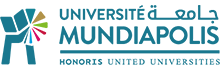

---

### Travaux Pratiques

## Les Embeddings avec LangChain et OpenAI

**Enseignant :** Pr. Habib AYAD  
**Classe :** 3ACINF DATA  
**Année universitaire :** 2026 – 2027

---

</div>

# 🧠 TP : Les Embeddings avec LangChain et OpenAI



## 🎯 Objectifs pédagogiques
À la fin de ce TP, vous serez capable de :
1. Expliquer ce qu'est un **embedding** (plongement vectoriel) et à quoi il sert.
2. Générer des embeddings avec `OpenAIEmbeddings` de **LangChain**.
3. Mesurer la **similarité** entre deux textes (similarité cosinus, distance euclidienne).
4. Construire un petit **moteur de recherche sémantique** avec un *vector store*.
5. **Visualiser** des embeddings en 2D.
6. Découper des documents longs (*chunking*) avant de les vectoriser.

## 📋 Plan du TP
| Partie | Contenu |
|---|---|
| 0 | Installation et configuration |
| 1 | Notions théoriques |
| 2 | Premier embedding |
| 3 | Mesurer la similarité |
| 4 | Recherche sémantique « à la main » |
| 5 | Vector Store LangChain |
| 6 | Visualisation 2D |
| 7 | Découpage de documents (chunking) |
| 8 | Exercices |

---
# Partie 0 — Installation et configuration

## 0.1 Installation des bibliothèques

| Bibliothèque | Rôle |
|---|---|
| `langchain-openai` | Connecteur LangChain vers les modèles OpenAI (dont les embeddings) |
| `langchain-core` | Objets de base de LangChain : `Document`, `InMemoryVectorStore`… |
| `langchain-text-splitters` | Outils pour découper des textes longs |
| `numpy` | Calcul numérique sur les vecteurs |
| `scikit-learn` | Réduction de dimension (PCA) pour la visualisation |
| `matplotlib` | Graphiques |
| `python-dotenv` | Lecture de la clé API depuis un fichier `.env` |

In [14]:
%pip install -qU langchain-openai langchain-core langchain-text-splitters numpy scikit-learn matplotlib python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0.2 Configuration de la clé API OpenAI

Pour appeler l'API OpenAI il faut une **clé API** (à créer sur https://platform.openai.com/api-keys).

> ⚠️ **Ne jamais écrire sa clé en clair dans un notebook partagé.**
> Deux méthodes sûres :
> - un fichier `.env` contenant `OPENAI_API_KEY=sk-...` (chargé par `load_dotenv()`),
> - ou une saisie masquée avec `getpass`.

**Fonctions utilisées :**
- `load_dotenv()` : lit le fichier `.env` du dossier courant et place ses variables dans l'environnement du processus.
- `os.environ.get(nom)` : renvoie la valeur d'une variable d'environnement, ou `None` si elle n'existe pas.
- `getpass.getpass(message)` : demande une saisie à l'utilisateur **sans l'afficher** à l'écran.

In [15]:
import os
import getpass
from dotenv import load_dotenv

load_dotenv()  # charge le fichier .env s'il existe

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("Entrez votre clé API OpenAI : ")

print("Clé API configurée ✅")

Clé API configurée ✅


---
# Partie 1 — Notions théoriques

## 1.1 Qu'est-ce qu'un embedding ?

Un **embedding** est une **représentation numérique d'un texte sous forme de vecteur** (une liste de nombres réels).

```
"Le chat dort sur le canapé"  ──►  [0.012, -0.087, 0.231, ..., 0.045]   (1536 nombres)
```

L'idée clé : **des textes de sens proche donnent des vecteurs proches** dans l'espace.

| Phrase | Proximité attendue |
|---|---|
| « Le chat dort » / « Le félin se repose » | 🟢 très proches (même sens, mots différents) |
| « Le chat dort » / « La bourse a chuté » | 🔴 éloignés |

C'est ce qui permet la **recherche sémantique** : on cherche par le *sens*, pas par les mots exacts.

## 1.2 À quoi ça sert ?
- 🔎 **Recherche sémantique** (moteur de recherche intelligent)
- 🤖 **RAG** (*Retrieval-Augmented Generation*) : donner à un LLM les bons documents pour répondre
- 🗂️ **Classification** et **clustering** de textes
- 🧭 **Recommandation** de contenus similaires
- 🚨 **Détection de doublons** ou d'anomalies

## 1.3 Les modèles d'embedding d'OpenAI

| Modèle | Dimension par défaut | Remarque |
|---|---|---|
| `text-embedding-3-small` | 1536 | Rapide et peu coûteux — **utilisé dans ce TP** |
| `text-embedding-3-large` | 3072 | Plus précis, plus cher |

> 💡 Les modèles `text-embedding-3-*` permettent de **réduire la dimension** via le paramètre `dimensions` (ex. 256), au prix d'une légère perte de précision.

---
# Partie 2 — Premier embedding

## 2.1 Créer le modèle d'embedding

### 📘 `OpenAIEmbeddings(...)`
Classe LangChain qui encapsule l'API d'embeddings d'OpenAI.

| Paramètre | Description |
|---|---|
| `model` | Nom du modèle (ex. `"text-embedding-3-small"`) |
| `dimensions` | *(optionnel)* taille des vecteurs produits (uniquement modèles `-3-`) |
| `api_key` | *(optionnel)* clé API ; par défaut lue dans `OPENAI_API_KEY` |
| `chunk_size` | *(optionnel)* nombre de textes envoyés par requête (par défaut 1000) |

L'objet créé expose deux méthodes principales :
- `embed_query(texte)` → **un** vecteur (pour une question / requête)
- `embed_documents(liste_de_textes)` → **une liste** de vecteurs (pour des documents)

In [16]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
print(embeddings)

client=<openai.resources.embeddings.Embeddings object at 0x00000286E34F0BD0> async_client=<openai.resources.embeddings.AsyncEmbeddings object at 0x00000286E34F3D10> model='text-embedding-3-small' dimensions=None deployment='text-embedding-ada-002' openai_api_version=None openai_api_base=None openai_api_type=None openai_proxy=None embedding_ctx_length=8191 openai_api_key=SecretStr('**********') openai_organization=None allowed_special=None disallowed_special=None chunk_size=1000 max_retries=2 request_timeout=None headers=None tiktoken_enabled=True tiktoken_model_name=None show_progress_bar=False model_kwargs={} skip_empty=False default_headers=None default_query=None retry_min_seconds=4 retry_max_seconds=20 http_client=None http_async_client=None check_embedding_ctx_length=True


## 2.2 Vectoriser une phrase

### 📘 `embeddings.embed_query(text: str) -> list[float]`
Envoie **un seul texte** à l'API et renvoie son embedding sous forme de liste de `float`.
On l'utilise typiquement pour la **requête** de l'utilisateur dans une recherche.

In [17]:
phrase = "Le chat dort paisiblement sur le canapé."
vecteur = embeddings.embed_query(phrase)

print("Type             :", type(vecteur))
print("Dimension        :", len(vecteur))
print("5 premières val. :", vecteur[:5])

AuthenticationError: Error code: 401 - {'error': {'message': 'Incorrect API key provided: AQ.Ab8RN*****************************************estw. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}}

🧐 **Observation :** le vecteur contient **1536 nombres**. Pris isolément, chacun n'a pas de signification lisible : c'est la **position globale** du vecteur dans l'espace qui encode le sens.

## 2.3 Vectoriser plusieurs documents

### 📘 `embeddings.embed_documents(texts: list[str]) -> list[list[float]]`
Vectorise **une liste de textes** en regroupant les appels à l'API (plus efficace qu'une boucle sur `embed_query`).
Renvoie une liste de vecteurs, **dans le même ordre** que les textes fournis.

In [ ]:
phrases = [
    "Le chat dort paisiblement sur le canapé.",
    "Un félin se repose tranquillement sur le sofa.",
    "Le chien court dans le jardin.",
    "La bourse de Paris a fortement chuté aujourd'hui.",
    "Les marchés financiers sont en baisse.",
    "J'adore cuisiner des pâtes à la carbonara.",
]

vecteurs = embeddings.embed_documents(phrases)

print("Nombre de vecteurs :", len(vecteurs))
print("Dimension de chacun :", len(vecteurs[0]))

## 2.4 Réduire la dimension (optionnel)

Le paramètre `dimensions` produit des vecteurs plus courts : moins de mémoire et des calculs plus rapides.

In [ ]:
embeddings_256 = OpenAIEmbeddings(model="text-embedding-3-small", dimensions=256)
v256 = embeddings_256.embed_query(phrase)
print("Dimension réduite :", len(v256))

---
# Partie 3 — Mesurer la similarité entre textes

## 3.1 La similarité cosinus

Elle mesure l'**angle** entre deux vecteurs $A$ et $B$ :

$$\text{cos}(A, B) = \frac{A \cdot B}{\|A\| \times \|B\|}$$

| Valeur | Interprétation |
|---|---|
| ≈ 1 | Sens très proche |
| ≈ 0 | Sans rapport |
| < 0 | Sens opposé (rare avec les embeddings de texte) |

> 💡 Les embeddings OpenAI sont **normalisés** (norme = 1) : la similarité cosinus est alors égale au simple **produit scalaire**.

### 📘 Fonctions NumPy utilisées
- `np.array(liste)` : convertit une liste Python en tableau NumPy pour le calcul vectoriel.
- `np.dot(a, b)` : produit scalaire $\sum a_i b_i$.
- `np.linalg.norm(a)` : norme euclidienne $\sqrt{\sum a_i^2}$ (la « longueur » du vecteur).

In [ ]:
import numpy as np

def similarite_cosinus(a, b):
    '''
    Calcule la similarité cosinus entre deux vecteurs.

    Paramètres
    ----------
    a, b : list[float] ou np.ndarray
        Les deux vecteurs à comparer (même dimension).

    Retour
    ------
    float : valeur entre -1 et 1 (1 = même direction = même sens).
    '''
    a, b = np.array(a), np.array(b)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))


print("Norme d'un embedding OpenAI :", round(np.linalg.norm(vecteurs[0]), 4))
print()
print(f"chat  vs félin  : {similarite_cosinus(vecteurs[0], vecteurs[1]):.3f}")
print(f"chat  vs chien  : {similarite_cosinus(vecteurs[0], vecteurs[2]):.3f}")
print(f"chat  vs bourse : {similarite_cosinus(vecteurs[0], vecteurs[3]):.3f}")
print(f"bourse vs marchés : {similarite_cosinus(vecteurs[3], vecteurs[4]):.3f}")

🧐 **Observation :** « chat » et « félin » sont très proches **alors qu'ils ne partagent presque aucun mot**. C'est toute la puissance des embeddings.

## 3.2 La distance euclidienne

Autre mesure possible : la distance « à vol d'oiseau » entre deux points.

$$d(A, B) = \|A - B\| = \sqrt{\sum (a_i - b_i)^2}$$

Ici, **plus la distance est petite, plus les textes sont proches** (c'est l'inverse du cosinus).

In [ ]:
def distance_euclidienne(a, b):
    '''
    Calcule la distance euclidienne entre deux vecteurs.

    Retour
    ------
    float : >= 0. Plus la valeur est petite, plus les textes sont proches.
    '''
    return float(np.linalg.norm(np.array(a) - np.array(b)))


print(f"chat vs félin  : {distance_euclidienne(vecteurs[0], vecteurs[1]):.3f}")
print(f"chat vs bourse : {distance_euclidienne(vecteurs[0], vecteurs[3]):.3f}")

## 3.3 Matrice de similarité

On calcule la similarité de **chaque phrase avec chaque autre**, puis on l'affiche sous forme de carte de chaleur (*heatmap*).

### 📘 Fonctions utilisées
- `M @ M.T` : produit matriciel ; comme les vecteurs sont normalisés, chaque case $(i, j)$ vaut la similarité cosinus entre la phrase $i$ et la phrase $j$.
- `plt.imshow(matrice, cmap=...)` : affiche une matrice comme une image colorée.
- `plt.colorbar()` : ajoute la légende des couleurs.
- `plt.xticks / plt.yticks` : place les étiquettes sur les axes.
- `plt.text(x, y, texte)` : écrit un texte à une position donnée du graphique.

In [ ]:
import matplotlib.pyplot as plt

M = np.array(vecteurs)
matrice_sim = M @ M.T

etiquettes = [p[:25] + "…" for p in phrases]

plt.figure(figsize=(8, 6))
plt.imshow(matrice_sim, cmap="viridis")
plt.colorbar(label="Similarité cosinus")
plt.xticks(range(len(phrases)), etiquettes, rotation=45, ha="right")
plt.yticks(range(len(phrases)), etiquettes)
for i in range(len(phrases)):
    for j in range(len(phrases)):
        plt.text(j, i, f"{matrice_sim[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
plt.title("Matrice de similarité entre phrases")
plt.tight_layout()
plt.show()

---
# Partie 4 — Recherche sémantique « à la main »

Avant d'utiliser les outils de LangChain, construisons nous-mêmes un mini moteur de recherche pour comprendre le principe :

1. **Indexation** : on vectorise une fois tous les documents (`embed_documents`).
2. **Requête** : on vectorise la question (`embed_query`).
3. **Comparaison** : on calcule la similarité question ↔ chaque document.
4. **Classement** : on renvoie les *k* documents les plus similaires.

### 📘 Fonctions utilisées
- `np.argsort(tableau)` : renvoie les **indices** qui trieraient le tableau par ordre croissant.
- `[::-1]` : inverse l'ordre (pour avoir le plus similaire en premier).

In [ ]:
base_connaissances = [
    "Python est un langage de programmation polyvalent et facile à apprendre.",
    "La tour Eiffel a été construite pour l'Exposition universelle de 1889.",
    "Les embeddings transforment du texte en vecteurs numériques.",
    "Le football est le sport le plus populaire au monde.",
    "LangChain est un framework pour développer des applications avec des LLM.",
    "La photosynthèse permet aux plantes de produire de l'énergie à partir de la lumière.",
    "Marrakech est une ville célèbre pour sa place Jemaa el-Fna.",
    "Les réseaux de neurones s'inspirent du fonctionnement du cerveau.",
]

# Étape 1 : indexation (une seule fois)
vecteurs_base = np.array(embeddings.embed_documents(base_connaissances))


def recherche_semantique(question, k=3):
    '''
    Renvoie les k documents de la base les plus proches de la question.

    Paramètres
    ----------
    question : str
        Texte de la requête.
    k : int
        Nombre de résultats à renvoyer.

    Retour
    ------
    list[tuple[float, str]] : couples (score, document), du plus au moins similaire.
    '''
    v_question = np.array(embeddings.embed_query(question))   # étape 2
    scores = vecteurs_base @ v_question                        # étape 3
    meilleurs = np.argsort(scores)[::-1][:k]                   # étape 4
    return [(float(scores[i]), base_connaissances[i]) for i in meilleurs]


for score, doc in recherche_semantique("Comment fonctionne l'intelligence artificielle ?"):
    print(f"{score:.3f}  |  {doc}")

In [ ]:
# Essayez d'autres questions !
for q in ["monument parisien", "outil pour créer un chatbot", "voyage au Maroc"]:
    print(f"\n🔎 {q}")
    for score, doc in recherche_semantique(q, k=2):
        print(f"   {score:.3f}  |  {doc}")

🧐 **Observation :** la requête « monument parisien » trouve la tour Eiffel **sans** que les mots « monument » ou « parisien » apparaissent dans le document.

---
# Partie 5 — Le Vector Store de LangChain

Un **vector store** (base vectorielle) automatise ce que nous venons de faire : il **stocke** les documents avec leurs embeddings et **recherche** les plus proches.
En production on utilise FAISS, Chroma, Pinecone, pgvector… Ici on prend `InMemoryVectorStore` (en mémoire, sans installation).

## 5.1 L'objet `Document`

### 📘 `Document(page_content: str, metadata: dict = {})`
Unité de base de LangChain pour représenter un texte.
- `page_content` : le texte lui-même.
- `metadata` : un dictionnaire d'informations complémentaires (source, auteur, catégorie, date…), très utile pour **filtrer** ou **citer** les sources.

In [ ]:
from langchain_core.documents import Document

documents = [
    Document(page_content="Python est un langage de programmation polyvalent.", metadata={"categorie": "informatique"}),
    Document(page_content="LangChain facilite la création d'applications avec des LLM.", metadata={"categorie": "informatique"}),
    Document(page_content="Les embeddings représentent le sens d'un texte par un vecteur.", metadata={"categorie": "informatique"}),
    Document(page_content="La tour Eiffel mesure environ 330 mètres.", metadata={"categorie": "tourisme"}),
    Document(page_content="Chefchaouen est surnommée la perle bleue du Maroc.", metadata={"categorie": "tourisme"}),
    Document(page_content="Le Real Madrid a remporté de nombreuses Ligues des champions.", metadata={"categorie": "sport"}),
    Document(page_content="Le marathon est une course de 42,195 km.", metadata={"categorie": "sport"}),
]

print(documents[0])
print("Texte     :", documents[0].page_content)
print("Métadonnées :", documents[0].metadata)

## 5.2 Créer le vector store

### 📘 `InMemoryVectorStore.from_documents(documents, embedding)`
Méthode de classe qui :
1. calcule l'embedding de chaque document avec le modèle `embedding`,
2. stocke textes + vecteurs + métadonnées en mémoire,
3. renvoie le vector store prêt à être interrogé.

> Il existe aussi `from_texts(textes, embedding, metadatas=...)` pour partir de simples chaînes.

In [ ]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore.from_documents(documents, embedding=embeddings)
print("Vector store créé ✅")

## 5.3 Rechercher des documents

### 📘 `vector_store.similarity_search(query, k=4)`
Vectorise `query`, puis renvoie la liste des `k` **`Document`** les plus proches.

### 📘 `vector_store.similarity_search_with_score(query, k=4)`
Identique, mais renvoie des couples `(Document, score)` : pratique pour voir **à quel point** chaque résultat est pertinent.

In [ ]:
resultats = vector_store.similarity_search("Quel framework utiliser pour les LLM ?", k=2)
for doc in resultats:
    print(f"- {doc.page_content}  [{doc.metadata['categorie']}]")

In [ ]:
resultats = vector_store.similarity_search_with_score("une belle ville à visiter", k=3)
for doc, score in resultats:
    print(f"{score:.3f}  |  {doc.page_content}")

## 5.4 Filtrer par métadonnées

Avec `InMemoryVectorStore`, le paramètre `filter` accepte une **fonction** qui reçoit un `Document` et renvoie `True` s'il doit être conservé.
(Les autres vector stores utilisent souvent un dictionnaire, ex. `filter={"categorie": "sport"}`.)

In [ ]:
def seulement_sport(doc: Document) -> bool:
    '''Garde uniquement les documents de la catégorie "sport".'''
    return doc.metadata.get("categorie") == "sport"

resultats = vector_store.similarity_search("compétition", k=3, filter=seulement_sport)
for doc in resultats:
    print("-", doc.page_content)

## 5.5 Ajouter des documents

### 📘 `vector_store.add_documents(documents)`
Vectorise et ajoute de nouveaux documents à un vector store existant. Renvoie la liste de leurs identifiants.

In [ ]:
ids = vector_store.add_documents([
    Document(page_content="Le couscous est un plat traditionnel du Maghreb.", metadata={"categorie": "cuisine"}),
])
print("Identifiants ajoutés :", ids)

for doc in vector_store.similarity_search("spécialité culinaire marocaine", k=1):
    print("-", doc.page_content)

## 5.6 Transformer le vector store en *retriever*

### 📘 `vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 2})`
Crée un **retriever** : un objet standard de LangChain qui prend une question et renvoie des documents.
C'est la brique utilisée dans les chaînes **RAG**.

| `search_type` | Comportement |
|---|---|
| `"similarity"` | Les k plus proches (par défaut) |
| `"mmr"` | *Maximal Marginal Relevance* : pertinents **et** variés (évite les doublons) |
| `"similarity_score_threshold"` | Seulement ceux au-dessus d'un score minimum |

### 📘 `retriever.invoke(question)`
Méthode standard (interface *Runnable*) qui exécute la recherche et renvoie une liste de `Document`.

In [ ]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 2})

for doc in retriever.invoke("apprendre à coder"):
    print("-", doc.page_content)

---
# Partie 6 — Visualiser les embeddings en 2D

Impossible de dessiner un espace à 1536 dimensions ! On utilise une **réduction de dimension** pour projeter les vecteurs en 2D tout en conservant au mieux leurs distances.

### 📘 `PCA(n_components=2)` (scikit-learn)
**Analyse en Composantes Principales** : trouve les 2 directions qui expliquent le plus de variance dans les données.
- `pca.fit_transform(X)` : apprend ces directions sur `X` **et** projette les données → tableau de forme `(n, 2)`.
- `pca.explained_variance_ratio_` : part de l'information conservée par chaque axe.

### 📘 `plt.scatter(x, y, c=..., label=...)`
Dessine un nuage de points.

In [ ]:
from sklearn.decomposition import PCA

corpus = {
    "animaux":  ["Le chat miaule", "Le chien aboie", "Le lion rugit dans la savane", "Les oiseaux chantent le matin"],
    "finance":  ["La bourse a chuté", "Les taux d'intérêt augmentent", "L'inflation ralentit", "Le dollar se renforce"],
    "cuisine":  ["Recette de tajine aux pruneaux", "Faire cuire les pâtes al dente", "Préparer une pâte à crêpes", "Griller des légumes au four"],
    "sport":    ["Le joueur marque un but", "Le marathon de Casablanca", "Match de tennis serré", "Entraînement de natation"],
}

textes, categories = [], []
for cat, liste in corpus.items():
    textes += liste
    categories += [cat] * len(liste)

X = np.array(embeddings.embed_documents(textes))

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)
print("Variance expliquée par les 2 axes :", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(9, 7))
for cat in corpus:
    idx = [i for i, c in enumerate(categories) if c == cat]
    plt.scatter(X_2d[idx, 0], X_2d[idx, 1], label=cat, s=80)
    for i in idx:
        plt.annotate(textes[i], (X_2d[i, 0], X_2d[i, 1]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.legend()
plt.title("Embeddings projetés en 2D (PCA)")
plt.grid(alpha=0.3)
plt.show()

🧐 **Observation :** les phrases d'une même thématique forment des **groupes (clusters)**, sans qu'on ait jamais indiqué les catégories au modèle.

> 💡 Pour aller plus loin, essayez `sklearn.manifold.TSNE` ou la bibliothèque `umap-learn`, qui conservent mieux les voisinages locaux.

---
# Partie 7 — Découper des documents longs (chunking)

Un modèle d'embedding a une **limite de taille d'entrée** (≈ 8 191 *tokens* pour OpenAI) et, surtout, un vecteur unique pour un très long texte « dilue » le sens.
On découpe donc les documents en **morceaux (chunks)** avant de les vectoriser.

### 📘 `RecursiveCharacterTextSplitter(chunk_size, chunk_overlap)`
Découpe un texte en essayant de couper d'abord aux paragraphes (`\n\n`), puis aux lignes (`\n`), puis aux espaces, pour garder des morceaux cohérents.

| Paramètre | Description |
|---|---|
| `chunk_size` | Taille maximale d'un morceau (en caractères) |
| `chunk_overlap` | Nombre de caractères **communs** entre deux morceaux consécutifs (évite de couper une idée en deux) |

### 📘 `splitter.split_text(texte)` → `list[str]`
### 📘 `splitter.create_documents([texte], metadatas=[...])` → `list[Document]`

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

texte_long = '''
Les embeddings sont au cœur des applications modernes de traitement du langage.
Ils permettent de représenter des mots, des phrases ou des documents entiers sous forme de vecteurs.

Le RAG, ou Retrieval-Augmented Generation, combine une recherche dans une base vectorielle
avec un modèle de langage. On récupère d'abord les passages pertinents, puis on les donne au LLM.

Le choix de la taille des morceaux est important. Des morceaux trop petits perdent le contexte,
des morceaux trop grands mélangent plusieurs idées et rendent la recherche moins précise.

Enfin, les métadonnées comme la source ou la page permettent de citer l'origine de chaque réponse.
'''

splitter = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=30)
chunks = splitter.create_documents([texte_long], metadatas=[{"source": "cours_embeddings"}])

print(f"{len(chunks)} morceaux créés\n")
for i, c in enumerate(chunks):
    print(f"--- Chunk {i} ({len(c.page_content)} caractères) ---")
    print(c.page_content, "\n")

In [ ]:
# On indexe les morceaux et on interroge
store_chunks = InMemoryVectorStore.from_documents(chunks, embedding=embeddings)

for doc, score in store_chunks.similarity_search_with_score("Comment choisir la taille des chunks ?", k=2):
    print(f"{score:.3f}  |  {doc.page_content[:100]}…  (source : {doc.metadata['source']})")

---
# Partie 8 — Exercices ✍️

### Exercice 1 — Synonymes et paraphrases
Écrivez 3 paires de phrases qui ont **le même sens avec des mots différents**, et 3 paires qui partagent **les mêmes mots mais un sens différent** (ex. « Il a pris l'avocat » : fruit / juriste).
Calculez la similarité cosinus de chaque paire. Que constatez-vous ?

In [ ]:

import os
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from langchain_google_genai import GoogleGenerativeAIEmbeddings

load_dotenv(override=True)

google_key = os.environ["OPENAI_API_KEY"]

embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001",
    google_api_key=google_key
)

def similarite_cosinus(a, b):
    a = np.array(a, dtype=float)
    b = np.array(b, dtype=float)

    return float(
        np.dot(a, b) /
        (np.linalg.norm(a) * np.linalg.norm(b))
    )

print("Configuration prête ✅")


Configuration prête ✅


In [ ]:


paires_similaires = [
    ("Le chat dort sur le canapé.",
     "Le félin se repose sur le sofa."),
    ("J'aime beaucoup le café.",
     "J'apprécie énormément le café."),
    ("Il fait très froid aujourd'hui.",
     "La température est très basse aujourd'hui.")
]

paires_ambigues = [
    ("La souris mange du fromage.",
     "La souris permet de déplacer le curseur sur l'écran."),
    ("Il a fermé la porte de la maison.",
     "Il a marqué la porte au football."),
    ("La banque accorde un crédit.",
     "Il s'assoit sur la banque de sable au bord de la rivière.")
]

def comparer_paires(paires, categorie):
    textes = []
    for a, b in paires:
        vecteurs = embeddings.embed_documents([a, b])
        score = similarite_cosinus(vecteurs[0], vecteurs[1])
        textes.append({
            "Catégorie": categorie,
            "Phrase 1": a,
            "Phrase 2": b,
            "Similarité cosinus": round(score, 4)
        })
    return textes

resultats_ex1 = (
    comparer_paires(paires_similaires, "Sens similaire")
    + comparer_paires(paires_ambigues, "Sens différent")
)

df_ex1 = pd.DataFrame(resultats_ex1)
display(df_ex1)


,Catégorie,Phrase 1,Phrase 2,Similarité cosinus
0,Sens similaire,Le chat dort sur le canapé.,Le félin se repose sur le sofa.,0.9363
1,Sens similaire,J'aime beaucoup le café.,J'apprécie énormément le café.,0.9690
2,Sens similaire,Il fait très froid aujourd'hui.,La température est très basse aujourd'hui.,0.9719
3,Sens différent,La souris mange du fromage.,La souris permet de déplacer le curseur sur l'...,0.8413
4,Sens différent,Il a fermé la porte de la maison.,Il a marqué la porte au football.,0.8339
5,Sens différent,La banque accorde un crédit.,Il s'assoit sur la banque de sable au bord de ...,0.7834


Les paraphrases et les phrases exprimant une idée similaire devraient généralement présenter une similarité cosinus élevée. Les phrases contenant un même mot dans des contextes différents peuvent avoir des scores différents, car les embeddings prennent en compte le contexte. Toutefois, un score élevé ne garantit pas que deux phrases ont exactement le même sens.

### Observation — Exercice 1

Les phrases qui expriment un même sens ont généralement une similarité cosinus élevée, même lorsque leur formulation est différente. En revanche, lorsque des mots identiques sont utilisés dans des contextes différents, la similarité peut varier : les embeddings prennent en compte le contexte, mais ne distinguent pas toujours parfaitement toutes les ambiguïtés.

### Exercice 2 — Multilingue
Les embeddings OpenAI sont **multilingues**. Comparez la similarité entre :
- « J'aime le café » (français)
- « I love coffee » (anglais)
- « أحب القهوة » (arabe)
- « J'aime le football » (français)

La langue compte-t-elle plus que le sens ?

In [25]:


phrases = [
    ("Français", "J'aime le café"),
    ("Anglais", "I love coffee"),
    ("Arabe", "أحب القهوة")
]

vecteurs = embeddings.embed_documents(
    [phrase for langue, phrase in phrases]
)

resultats_ex2 = []

for i in range(len(phrases)):
    for j in range(i + 1, len(phrases)):
        score = similarite_cosinus(vecteurs[i], vecteurs[j])

        resultats_ex2.append({
            "Langue 1": phrases[i][0],
            "Phrase 1": phrases[i][1],
            "Langue 2": phrases[j][0],
            "Phrase 2": phrases[j][1],
            "Similarité cosinus": round(score, 4)
        })

df_ex2 = pd.DataFrame(resultats_ex2)
display(df_ex2)


,Langue 1,Phrase 1,Langue 2,Phrase 2,Similarité cosinus
0,Français,J'aime le café,Anglais,I love coffee,0.9298
1,Français,J'aime le café,Arabe,أحب القهوة,0.9332
2,Anglais,I love coffee,Arabe,أحب القهوة,0.9528


Les trois phrases expriment la même idée dans des langues différentes. Si leurs scores de similarité sont élevés, cela indique que le modèle multilingue représente des significations proches dans un espace vectoriel commun. Les scores peuvent néanmoins varier selon la langue et la formulation.

### Exercice 3 — Impact de la dimension
Créez trois modèles avec `dimensions=64`, `256` et `1536`. Pour la base de la partie 4, comparez le classement des résultats pour une même question. À partir de quelle dimension les résultats changent-ils ?

In [26]:

texte1 = "Le chat dort sur le canapé."
texte2 = "Le félin se repose sur le sofa."

dimensions = [64, 256, 1536]
resultats_ex3 = []

for dimension in dimensions:
    # Gemini accepte les dimensions à partir de 128
    dimension_api = 128 if dimension == 64 else dimension

    embeddings_dimension = GoogleGenerativeAIEmbeddings(
        model="gemini-embedding-001",
        google_api_key=google_key,
        output_dimensionality=dimension_api
    )

    vecteurs = embeddings_dimension.embed_documents([texte1, texte2])

    v1 = np.array(vecteurs[0], dtype=float)
    v2 = np.array(vecteurs[1], dtype=float)

    # Pour le test 64, on garde les 64 premières valeurs
    v1 = v1[:dimension]
    v2 = v2[:dimension]

    # Normalisation après réduction
    score = similarite_cosinus(v1, v2)

    resultats_ex3.append({
        "Dimension demandée": dimension,
        "Dimension du vecteur utilisé": len(v1),
        "Similarité cosinus": round(score, 4),
        "Stockage relatif": f"{dimension} valeurs"
    })

df_ex3 = pd.DataFrame(resultats_ex3)
display(df_ex3)


,Dimension demandée,Dimension du vecteur utilisé,Similarité cosinus,Stockage relatif
0,64,64,0.9790,64 valeurs
1,256,256,0.9517,256 valeurs
2,1536,1536,0.9288,1536 valeurs


La dimension détermine le nombre de valeurs utilisées pour représenter le sens d'un texte. Une dimension plus élevée augmente le stockage nécessaire, mais ne garantit pas automatiquement une meilleure similarité. Les scores peuvent varier selon la dimension et le modèle utilisé. Dans cette expérience, la dimension 64 est obtenue par réduction locale d'un vecteur de 128 valeurs, tandis que 256 et 1536 sont demandées directement au modèle.

### Exercice 4 — Mini FAQ intelligente
1. Créez une liste de 8 à 10 couples *question / réponse* (par exemple sur votre établissement).
2. Indexez **les questions** dans un `InMemoryVectorStore`, en plaçant la réponse dans les `metadata`.
3. Écrivez une fonction `repondre(question_utilisateur)` qui trouve la question la plus proche et renvoie sa réponse.
4. Bonus : si le meilleur score est inférieur à un seuil (ex. 0,4), renvoyez « Je ne sais pas ».

In [ ]:
# Votre code ici

### Exercice 5 — Classification sans entraînement (*zero-shot*)
Définissez des étiquettes (`"sport"`, `"politique"`, `"technologie"`, `"cuisine"`) et vectorisez-les.
Pour chaque nouvelle phrase, attribuez l'étiquette dont l'embedding est le plus proche. Testez sur 10 phrases et calculez le taux de réussite.

In [ ]:
# Votre code ici

---
# 📝 Récapitulatif

| Fonction / Classe | Rôle |
|---|---|
| `OpenAIEmbeddings(model=...)` | Crée le modèle d'embedding OpenAI |
| `embed_query(texte)` | Vectorise **un** texte (requête) |
| `embed_documents(textes)` | Vectorise **plusieurs** textes (documents) |
| `Document(page_content, metadata)` | Représente un texte et ses informations |
| `InMemoryVectorStore.from_documents(...)` | Crée une base vectorielle en mémoire |
| `similarity_search(query, k)` | Renvoie les k documents les plus proches |
| `similarity_search_with_score(query, k)` | Idem, avec les scores |
| `add_documents(docs)` | Ajoute des documents à la base |
| `as_retriever(...)` / `invoke(q)` | Interface standard de recherche (RAG) |
| `RecursiveCharacterTextSplitter` | Découpe les textes longs en morceaux |
| `PCA(n_components=2)` | Projette les vecteurs en 2D pour les visualiser |

## 🔑 À retenir
1. Un embedding transforme un texte en **vecteur** qui encode son **sens**.
2. Des textes de sens proche ⇒ des vecteurs proches (**similarité cosinus** élevée).
3. La recherche sémantique = vectoriser la requête + trouver les vecteurs les plus proches.
4. On **découpe** les longs documents et on ajoute des **métadonnées** avant d'indexer.
5. Ces briques constituent la base de tout système **RAG**.

## ➡️ Pour aller plus loin
- Remplacer `InMemoryVectorStore` par **FAISS** ou **Chroma** pour persister la base sur disque.
- Brancher le retriever sur un LLM (`ChatOpenAI`) pour construire un **chatbot RAG** complet.
- Documentation : https://python.langchain.com/docs/integrations/text_embedding/openai/